# Test Zarr cube

This notebook opens the Zarr store and runs a small computation to verify integrity.

In [1]:
import xarray as xr
from pathlib import Path
# Paths
repo_root = next(
    parent for parent in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    if (parent / "pyproject.toml").exists()
)
store = repo_root / "data" / "zarr" / "metref_sample_1month.zarr"

ds = xr.open_zarr(store, consolidated=False)
ds

<xarray.Dataset> Size: 114MB
Dimensions:       (time: 30, lat: 552, lon: 576)
Coordinates:
  * time          (time) datetime64[ns] 240B 2020-06-01 ... 2020-06-30
  * lat           (lat) float64 4kB -10.94 -10.89 -10.84 ... 16.51 16.56 16.61
  * lon           (lon) float64 5kB -17.18 -17.13 -17.08 ... 11.47 11.52 11.57
Data variables:
    METREF        (time, lat, lon) float32 38MB dask.array<chunksize=(1, 256, 256), meta=np.ndarray>
    quality_flag  (time, lat, lon) float64 76MB dask.array<chunksize=(1, 256, 256), meta=np.ndarray>
Attributes: (12/29)
    CDI:                        Climate Data Interface version 2.4.0 (https:/...
    Conventions:                CF-1.6
    institution:                IM-PT
    date_created:               2020-10-23T07:20:57Z
    algorithm_version:          1.3.2
    base_algorithm_version:     1.0.3
    ...                         ...
    westernmost_longitude:      80.0
    spatial_resolution:          0.05x 0.05
    geospatial_lat_units:       degrees_north
    geospatial_lon_units:       degrees_east
    netcdf_version_id:          netCDF4
    CDO:                        Climate Data Operators version 2.4.0 (https:/...

In [ ]:
ds.METREF.values

array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       ...,

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan

In [ ]:
# Example quick check
# (adjust variable name if needed)
ds.to_array().mean('time').compute()

In [4]:
from pathlib import Path
import sys

repo_root = next(
    parent for parent in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    if (parent / "pyproject.toml").exists()
)
module_dir = repo_root / "code" / "plot_utils"

print("Notebook folder:", repo_root)
print("Module folder exists:", module_dir.exists())
print("Module file exists:", (module_dir / "adaptive_cube_plot.py").exists())
sys.path.insert(0, str(module_dir))

from adaptive_cube_plot import plot_time_slices, plot_spatial_timeseries

Notebook folder: C:\Users\b1113715\Downloads\tutorial-repo
Module folder exists: True
Module file exists: True


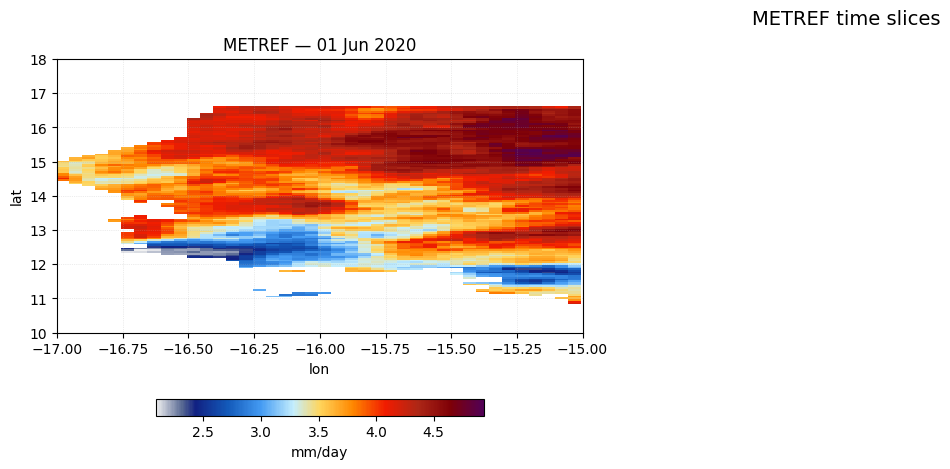

In [5]:
fig, axes = plot_time_slices(
    ds,
    var="METREF",
    time_index=[0],
    ncols=3,
    extent=[-17, -15, 10, 18],

)